# Coffee Sales Trend Analysis - Python EDA

I first did this project only with SQL and Power BI. In this notebook I use pandas to check the data quality,
clean a few columns and make some charts that were not in the dashboard.

**Steps**
1. Load the data and check data quality
2. Clean dates and rebuild the full order time
3. EDA charts (monthly trend, products, hours, weekdays, price changes)
4. Key findings

> Run this notebook from inside the `notebooks/` folder.

In [1]:
import os
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

DATA_PATH = '../data/coffee_data.csv'
CHART_DIR = '../images/charts'
os.makedirs(CHART_DIR, exist_ok=True)

## 1. Load data & data quality checks

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(3547, 11)


,hour_of_day,cash_type,money(Rs),coffee_name,Time_of_Day,Weekday,Month_name,Weekdaysort,Monthsort,Date,Time
0,10,card,38.7,Latte,Morning,Fri,Mar,5,3,3/1/2024,15:50.5
1,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,3/1/2024,19:22.5
2,12,card,38.7,Hot Chocolate,Afternoon,Fri,Mar,5,3,3/1/2024,20:18.1
3,13,card,28.9,Americano,Afternoon,Fri,Mar,5,3,3/1/2024,46:33.0
4,13,card,38.7,Latte,Afternoon,Fri,Mar,5,3,3/1/2024,48:14.6


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3547 entries, 0 to 3546
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   hour_of_day  3547 non-null   int64  
 1   cash_type    3547 non-null   str    
 2   money(Rs)    3547 non-null   float64
 3   coffee_name  3547 non-null   str    
 4   Time_of_Day  3547 non-null   str    
 5   Weekday      3547 non-null   str    
 6   Month_name   3547 non-null   str    
 7   Weekdaysort  3547 non-null   int64  
 8   Monthsort    3547 non-null   int64  
 9   Date         3547 non-null   str    
 10  Time         3547 non-null   str    
dtypes: float64(1), int64(3), str(7)
memory usage: 304.9 KB


In [4]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
print()
print(df['cash_type'].value_counts())
print()
print(df['coffee_name'].value_counts())

Missing values: 0
Duplicate rows: 0

cash_type
card    3547
Name: count, dtype: int64

coffee_name
Americano with Milk    809
Latte                  757
Americano              564
Cappuccino             486
Cortado                287
Hot Chocolate          276
Cocoa                  239
Espresso               129
Name: count, dtype: int64


**Notes**
- No missing values and no duplicate rows.
- `cash_type` is **card for all 3547 rows**, so there is nothing to compare between cash and card in this dataset.

In [5]:
# the Time column looks strange, let's check its format
print(df['Time'].head(10).tolist())

full_time = df['Time'].str.len() == 8
print('Rows with full hh:mm:ss time:', full_time.sum())
print('Rows with mm:ss.s time      :', (~full_time).sum())

['15:50.5', '19:22.5', '20:18.1', '46:33.0', '48:14.6', '39:47.7', '19:02.8', '39:03.6', '22:01.8', '23:15.9']
Rows with full hh:mm:ss time: 8
Rows with mm:ss.s time      : 3539


The `Time` column lost its hour when the file was saved (Excel format problem), so most values look like `15:50.5`
which is actually *minutes:seconds*. Only 8 rows have the full time. I will rebuild the full time using `hour_of_day`.

In [6]:
# Month_name / Monthsort do not have the year
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')
print('From', df['Date'].min().date(), 'to', df['Date'].max().date())

df.groupby([df['Date'].dt.year, 'Month_name']).size().loc[:, 'Mar']

From 2024-03-01 to 2025-03-23


Date
2024    175
2025    319
dtype: int64

The data runs from **1 March 2024 to 23 March 2025**, so there are two different Marches.
Grouping only by `Month_name` (like my first SQL queries did) adds them together.
I will use a `year_month` column instead.

## 2. Cleaning

In [7]:
def rebuild_time(row):
    t = row['Time']
    if len(t) == 8:            # already hh:mm:ss
        return t
    minutes, seconds = t.split(':')
    return f"{row['hour_of_day']:02d}:{int(minutes):02d}:{int(float(seconds)):02d}"

df['order_time'] = df.apply(rebuild_time, axis=1)
df['order_datetime'] = pd.to_datetime(df['Date'].dt.strftime('%Y-%m-%d') + ' ' + df['order_time'])
df['year_month'] = df['Date'].dt.to_period('M').astype(str)
df['is_weekend'] = df['Weekday'].isin(['Sat', 'Sun'])

# check: the hour of the rebuilt time should always match hour_of_day
print('Hour mismatches:', (df['order_datetime'].dt.hour != df['hour_of_day']).sum())
df[['Date', 'Time', 'hour_of_day', 'order_datetime', 'year_month']].head()

Hour mismatches:

 0


,Date,Time,hour_of_day,order_datetime,year_month
0,2024-03-01,15:50.5,10,2024-03-01 10:15:50,2024-03
1,2024-03-01,19:22.5,12,2024-03-01 12:19:22,2024-03
2,2024-03-01,20:18.1,12,2024-03-01 12:20:18,2024-03
3,2024-03-01,46:33.0,13,2024-03-01 13:46:33,2024-03
4,2024-03-01,48:14.6,13,2024-03-01 13:48:14,2024-03


In [8]:
# save a clean copy (same columns + the new ones)
clean_cols = ['order_datetime', 'Date', 'year_month', 'hour_of_day', 'Time_of_Day', 'Weekday', 'Weekdaysort',
              'is_weekend', 'coffee_name', 'money(Rs)', 'cash_type']
df[clean_cols].to_csv('../data/coffee_data_clean.csv', index=False)
print('saved data/coffee_data_clean.csv', df[clean_cols].shape)

saved data/coffee_data_clean.csv (3547, 11)


## 3. EDA

### 3.1 Monthly revenue and orders

            orders   revenue
year_month                  
2024-03        175   5905.20
2024-04        168   5719.56
2024-05        241   8164.42
2024-06        223   7617.76
2024-07        237   6915.94
2024-08        272   7613.84
2024-09        344   9988.64
2024-10        426  13891.16
2024-11        259   8590.54
2024-12        259   8237.74
2025-01        201   6398.86
2025-02        423  13215.48
2025-03        319   9986.44


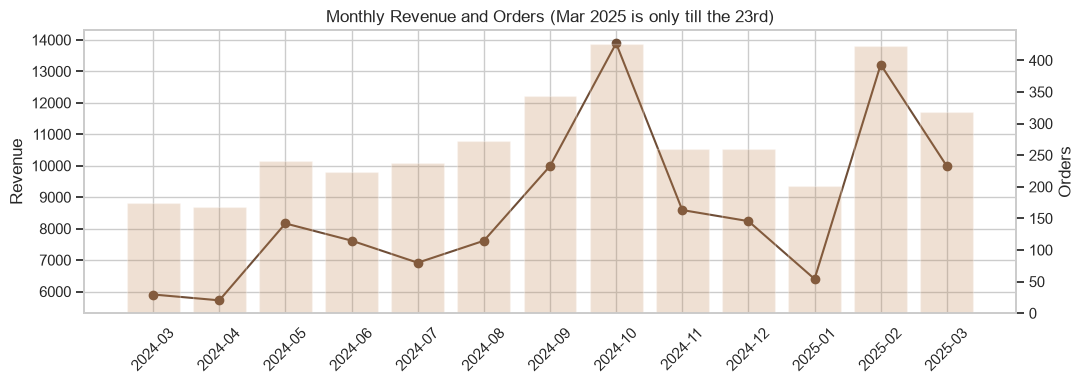

In [9]:
monthly = df.groupby('year_month').agg(orders=('coffee_name', 'count'), revenue=('money(Rs)', 'sum'))
print(monthly.round(2))

fig, ax1 = plt.subplots(figsize=(11,4))
ax1.plot(monthly.index, monthly['revenue'], marker='o', color='#6F4E37', label='Revenue')
ax1.set_ylabel('Revenue')
ax2 = ax1.twinx()
ax2.bar(monthly.index, monthly['orders'], alpha=0.25, color='#C08552', label='Orders')
ax2.set_ylabel('Orders')
ax2.grid(False)
ax1.set_title('Monthly Revenue and Orders (Mar 2025 is only till the 23rd)')
ax1.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '1_monthly_revenue.png'))
plt.show()

### 3.2 Revenue and orders by coffee

                     orders   revenue  revenue_share_%
coffee_name                                           
Latte                   757  26875.30             23.9
Americano with Milk     809  24751.12             22.1
Cappuccino              486  17439.14             15.5
Americano               564  14650.26             13.1
Hot Chocolate           276   9933.46              8.8
Cocoa                   239   8521.16              7.6
Cortado                 287   7384.86              6.6
Espresso                129   2690.28              2.4


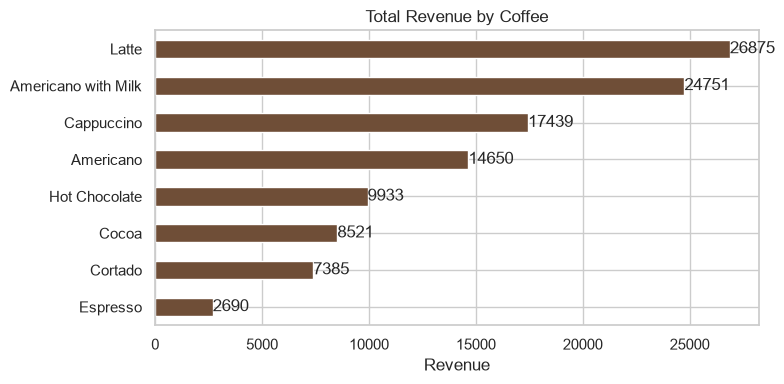

In [10]:
products = df.groupby('coffee_name').agg(orders=('coffee_name', 'count'), revenue=('money(Rs)', 'sum'))
products['revenue_share_%'] = (products['revenue'] / products['revenue'].sum() * 100).round(1)
products = products.sort_values('revenue', ascending=False)
print(products.round(2))

plt.figure(figsize=(8,4))
ax = products['revenue'].sort_values().plot(kind='barh', color='#6F4E37')
ax.bar_label(ax.containers[0], fmt='%.0f')
plt.title('Total Revenue by Coffee')
plt.xlabel('Revenue')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '2_revenue_by_coffee.png'))
plt.show()

### 3.3 Orders by hour

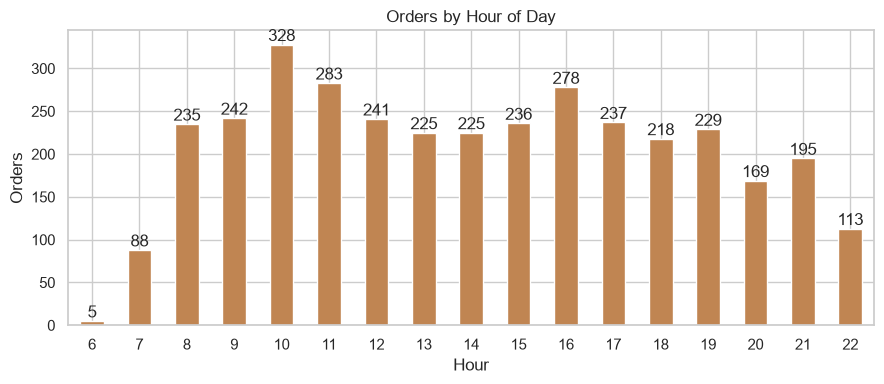

In [11]:
hourly = df.groupby('hour_of_day').size()

plt.figure(figsize=(9,4))
ax = hourly.plot(kind='bar', color='#C08552')
ax.bar_label(ax.containers[0])
plt.title('Orders by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Orders')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '3_orders_by_hour.png'))
plt.show()

### 3.4 Weekday vs weekend
Total revenue per weekday is not a fair comparison for weekday vs weekend, so I also check the **average revenue per day**.

            count    mean
is_weekend               
Weekday       272  309.47
Weekend       109  257.52


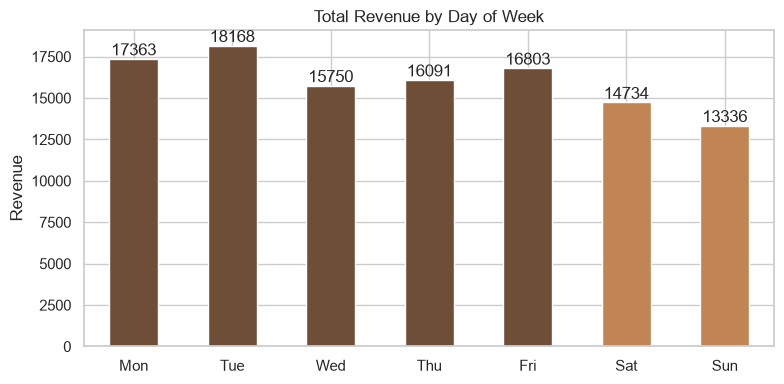

In [12]:
weekday_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
weekday_rev = df.groupby('Weekday')['money(Rs)'].sum().reindex(weekday_order)

daily = df.groupby(['Date', 'is_weekend'])['money(Rs)'].sum().reset_index()
print(daily.groupby('is_weekend')['money(Rs)'].agg(['count', 'mean']).round(2).rename(index={False: 'Weekday', True: 'Weekend'}))

colors = ['#6F4E37'] * 5 + ['#C08552'] * 2
plt.figure(figsize=(8,4))
ax = weekday_rev.plot(kind='bar', color=colors)
ax.bar_label(ax.containers[0], fmt='%.0f')
plt.title('Total Revenue by Day of Week')
plt.xlabel('')
plt.ylabel('Revenue')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '4_weekday_revenue.png'))
plt.show()

### 3.5 When is the shop busy? (hour x weekday)

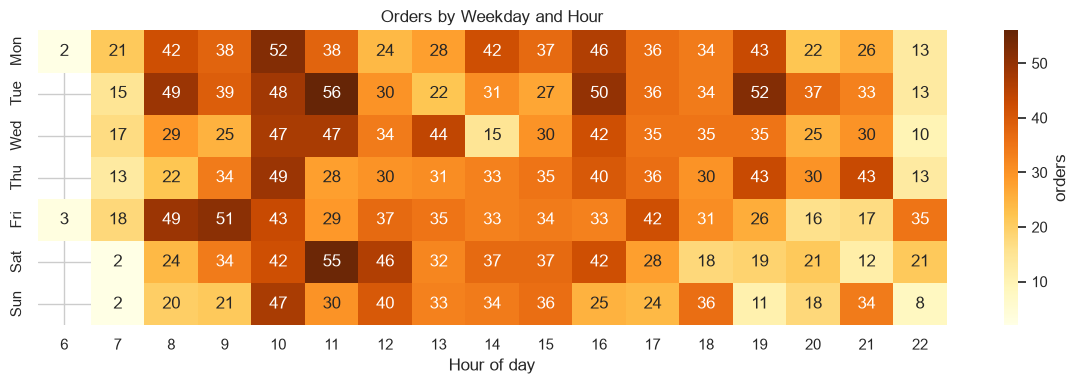

In [13]:
heat = df.pivot_table(index='Weekday', columns='hour_of_day', values='coffee_name', aggfunc='count').reindex(weekday_order)

plt.figure(figsize=(12,4))
sns.heatmap(heat, cmap='YlOrBr', annot=True, fmt='.0f', cbar_kws={'label': 'orders'})
plt.title('Orders by Weekday and Hour')
plt.xlabel('Hour of day')
plt.ylabel('')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '5_hour_weekday_heatmap.png'))
plt.show()

### 3.6 Coffee preference by time of day

Time_of_Day          Morning  Afternoon  Night
coffee_name                                   
Americano with Milk      331        239    239
Latte                    215        270    272
Americano                219        233    112
Cappuccino               122        164    200
Cortado                  143         88     56
Hot Chocolate             49         80    147
Cocoa                     58         75    106
Espresso                  44         56     29


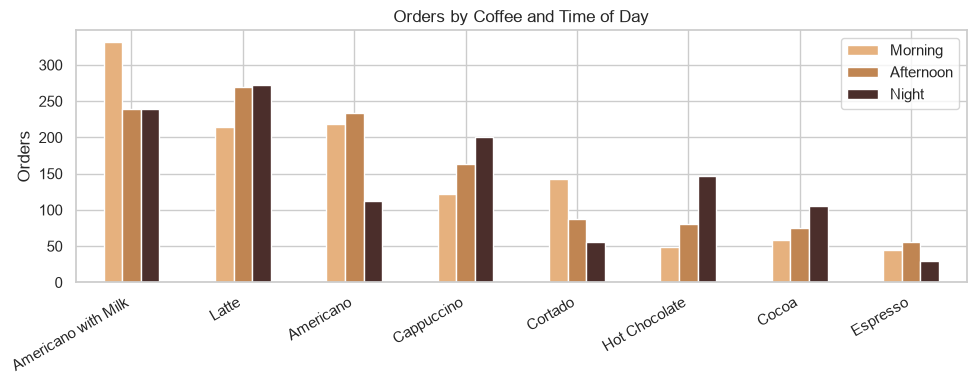

In [14]:
daypart = pd.crosstab(df['coffee_name'], df['Time_of_Day'])[['Morning', 'Afternoon', 'Night']]
daypart = daypart.loc[daypart.sum(axis=1).sort_values(ascending=False).index]
print(daypart)

daypart.plot(kind='bar', figsize=(10,4), color=['#E6B17E', '#C08552', '#4B2E2B'])
plt.title('Orders by Coffee and Time of Day')
plt.xlabel('')
plt.ylabel('Orders')
plt.xticks(rotation=30, ha='right')
plt.legend(title='')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '6_coffee_by_daypart.png'))
plt.show()

### 3.7 Price changes
While checking the data I noticed every coffee has 4 different prices. This chart shows the price of each coffee over time.

                                     min        max  count
coffee_name         money(Rs)                             
Americano           23.02     2024-07-08 2024-09-27     98
                    25.96     2024-09-29 2025-03-23    341
                    27.92     2024-04-21 2024-07-05     72
                    28.90     2024-03-01 2024-04-20     53
Americano with Milk 27.92     2024-07-06 2024-09-28    222
                    30.86     2024-09-28 2025-03-22    389
                    32.82     2024-04-20 2024-07-05    147
                    33.80     2024-03-01 2024-04-20     51


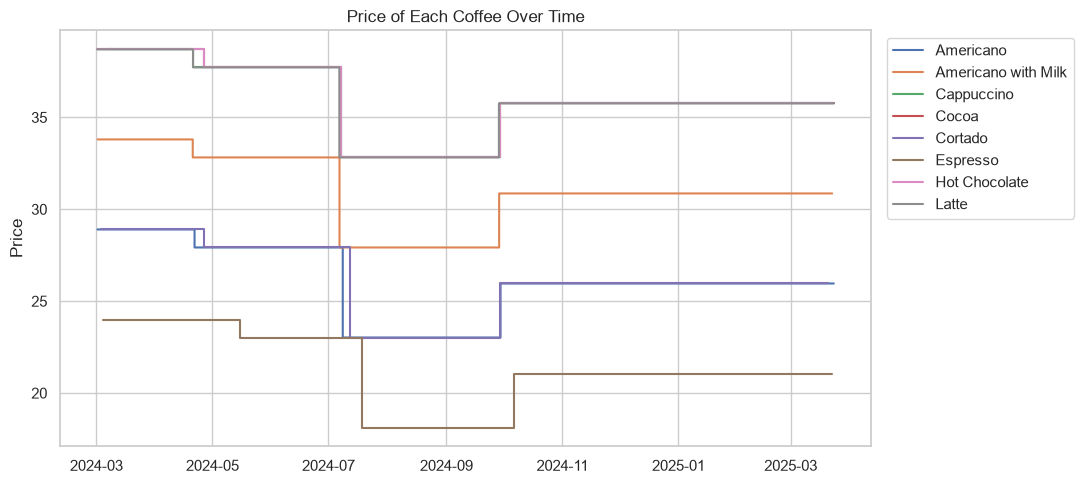

            orders  avg_ticket
year_month                    
2024-03        175       33.74
2024-04        168       34.04
2024-05        241       33.88
2024-06        223       34.16
2024-07        237       29.18
2024-08        272       27.99
2024-09        344       29.04
2024-10        426       32.61
2024-11        259       33.17
2024-12        259       31.81
2025-01        201       31.84
2025-02        423       31.24
2025-03        319       31.31


In [15]:
price_history = df.groupby(['coffee_name', 'money(Rs)'])['Date'].agg(['min', 'max', 'count'])
print(price_history.head(8))

plt.figure(figsize=(11,5))
for name, group in df.sort_values('order_datetime').groupby('coffee_name'):
    plt.step(group['order_datetime'], group['money(Rs)'], where='post', label=name)
plt.title('Price of Each Coffee Over Time')
plt.ylabel('Price')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(CHART_DIR, '7_price_history.png'))
plt.show()

# average ticket by month to see if the price cut changed the number of orders
monthly['avg_ticket'] = (monthly['revenue'] / monthly['orders']).round(2)
print(monthly[['orders', 'avg_ticket']])

## 4. Key Findings

**Overall**
- 3,547 orders and **Rs 1,12,245** total revenue between 1 Mar 2024 and 23 Mar 2025.
- Average order value is **Rs 31.65** and the shop makes about **Rs 295 and 9 orders per day** (381 days with sales).

**Products**
- **Latte** brings the most revenue (23.9%) but **Americano with Milk** is ordered the most (809 orders).
- The top 4 coffees (Latte, Americano with Milk, Cappuccino, Americano) make about **75% of revenue**. Espresso is only 2.4%.

**Time**
- The busiest hour is **10 AM** (328 orders) and there is a second smaller peak at **4 PM** (278 orders).
- Revenue is almost equal across Morning (32%), Afternoon (34%) and Night (34%). In my first README I wrote that night orders drop, which was not correct.
- Morning is mostly Americano with Milk and Cortado. At night people order more Latte, Cappuccino, Hot Chocolate and Cocoa.

**Days and months**
- Weekdays are busier than weekends: **Rs 309 per weekday vs Rs 258 per weekend day** (about 17% less on weekends). Tuesday is the best day, Sunday the weakest.
- The best months were **Oct 2024** (Rs 13,891) and **Feb 2025** (Rs 13,215). April 2024 and January 2025 were the weakest.

**Prices**
- Every coffee changed price 3 times. Prices were cut in **July 2024** (for example Latte 37.72 to 32.82) and raised again at the end of **September 2024**.
- The average ticket dropped from about 34 to 28-29 during the cheaper months, but the biggest month (October) came *after* prices went up again, so price alone does not explain the demand.

**Suggestions**
1. Keep extra staff around 9-11 AM and 4 PM, especially Monday and Tuesday.
2. Try weekend offers, since a weekend day makes about 17% less than a weekday.
3. Milk based drinks (Latte + Americano with Milk) are almost half of revenue, so milk stock should never run out.
4. Push chocolate / cocoa drinks in the evening when they sell more.

**Limitations**
- Only one shop and about one year of data, and every payment is card.
- The amount column is called `money(Rs)` in the source file, so I kept that name.